# ANALISIS DE COMPONENTES EN VALUACIÓN DE OPCINES VERSIÓN (LONG-CALL/PUT)
Carlos Santiago Nava Pulido

## COMPARACIÓN BLACK-SCHOLES Y MONTECARLO

In [47]:
#region establesco la función monte_carlo_option_price

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)
def monte_carlo_option_pricer(S0, K, T, r, sigma, num_simulations, num_steps, option_type):

    dt = T / num_steps
    drift = (r - 0.5 * sigma**2) * dt
    diffusion = sigma * np.sqrt(dt)
    simulated_prices = np.zeros(num_simulations)
    for i in range(num_simulations):
        Z = np.random.normal(0, 1, num_steps)
        log_returns = drift + diffusion * Z
        price_path = S0 * np.exp(np.cumsum(log_returns))
        simulated_prices[i] = price_path[-1]

    if option_type == 'call':
        payoffs = np.maximum(0, simulated_prices - K)
    elif option_type == 'put':
        payoffs = np.maximum(0, K - simulated_prices)
    else:
        raise ValueError("option_type debe ser 'call' o 'put'")

    option_price = np.exp(-r * T) * np.mean(payoffs)
    return option_price, simulated_prices, payoffs

#endregion

In [64]:
#region establesco una función black_scholes
import scipy.stats as stats
def black_scholes(S0, K, T, r, sigma, option_type):
    d_1 = (np.log(S0/K)+(r+.5*sigma**2)*T)/(sigma*np.sqrt(T))
    d_2 = d_1 - sigma*np.sqrt(T)
    if option_type == "call":
        prima = S0* stats.norm.cdf(d_1) - K*np.exp(-r*T)*stats.norm.cdf(d_2)

    elif option_type == "put":
        prima = K*np.exp(-r*T)*stats.norm.cdf(-d_2)-S0* stats.norm.cdf(-d_1)

    return prima
#endregion


el precio del call black scholes: 10.450583572185565
el precio de put de black scholes: 5.573526022256971
 precio del call montecarlo: 10.499477533698762
 precio del put montecarlo: 5.662531073469123


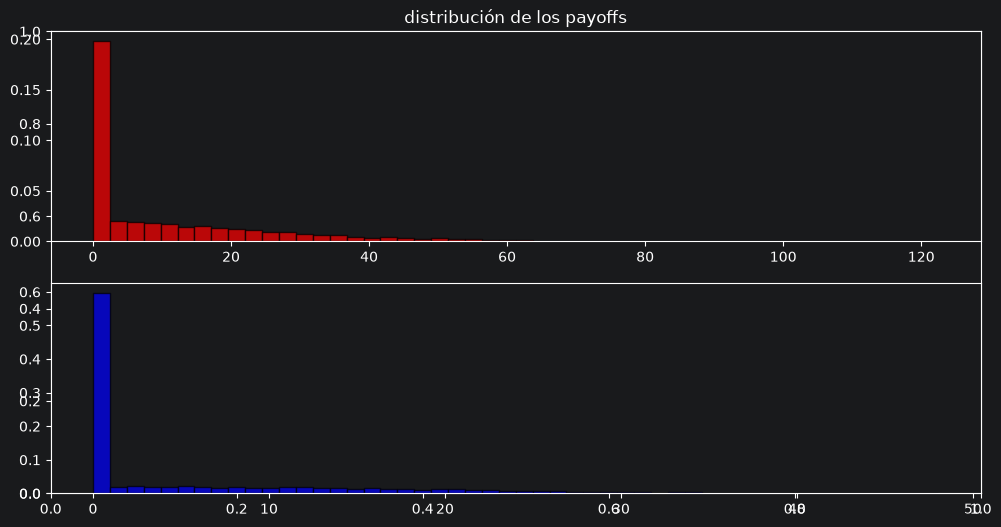

In [67]:
#region parámetros base
S0 = 100
K = 100
r = .05
sigma = .20
T = 1
num_simulaciones = 10000

prima_call_bs=black_scholes(S0, K, T, r, sigma, 'call')
prima_put_bs=black_scholes(S0, K, T, r, sigma, 'put')

print(f'el precio del call black scholes: {prima_call_bs}')
print(f'el precio de put de black scholes: {prima_put_bs}')

prima_call, precios_call, payoffs_call = monte_carlo_option_pricer(S0, K, T, r, sigma, num_simulaciones, 252, option_type='call')

prima_put, precios_put, payoffs_put = monte_carlo_option_pricer(S0, K, T, r, sigma, num_simulaciones, 252, option_type='put')

# precio prima
print(f' precio del call montecarlo: {prima_call}')
print(f' precio del put montecarlo: {prima_put}')

plt.figure(figsize=(12, 6))
plt.title('distribución de los payoffs')
plt.subplot(2,1,1)
plt.hist(payoffs_call, bins=50, density=True, alpha=0.7, color='red', edgecolor='black')

plt.subplot(2,1,2)
plt.hist(payoffs_put, bins=50, density=True, alpha=0.7, color='blue', edgecolor='black')
plt.show()

#endregion

## ANALISIS DE SENSIBILIDAD SEGÚN EL PARAMETRO

In [50]:
#parametros
'''
Precio del activo (80, 90, 100, 110, 120)
Strike (80, 90, 100, 110, 120)
Volatilidad (10%, 20%, 30%, 40%, 50%)
Tiempo (0.25, 0.5, 1, 1.5, 2)
Rendimiento (5%, 10%, 15%, 20%)
'''

S_movil = np.arange(70,130, step=10)
K_movil = np.arange(80,130, step=10)
sigma_movil = np.arange(.10,.70, .10)
T_movil = np.arange(.25,2.5,.25)
r_movil = np.arange(.05,.25,.05)


### Spots price analisis

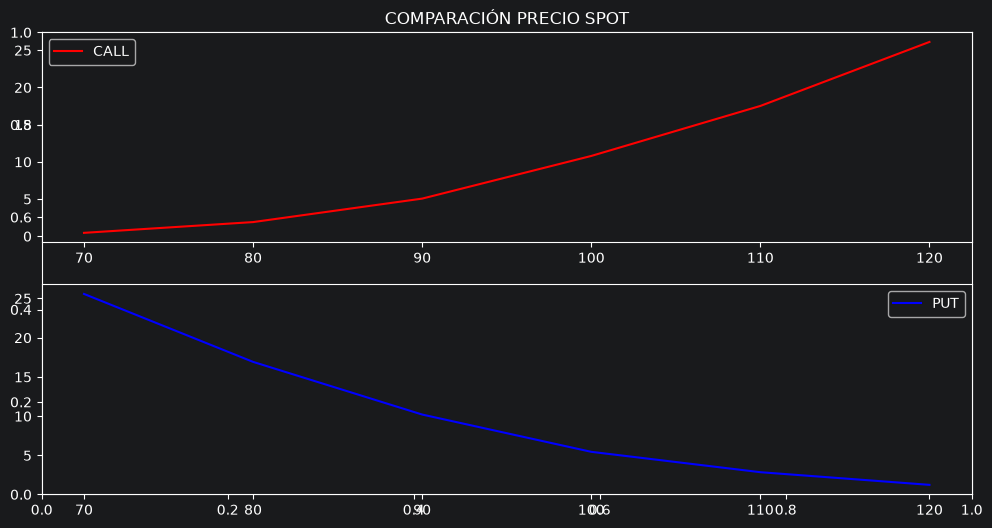

,call,put,dif_call,dif_put
70,0.461222,25.576734,NaN,NaN
80,1.907997,16.921652,1.446775,-8.655082
90,5.062769,10.214118,3.154772,-6.707534
100,10.796408,5.465463,5.733639,-4.748655
110,17.518374,2.870862,6.721966,-2.594601
120,26.121856,1.259863,8.603482,-1.610999


In [77]:
call_S = []
put_S = []
for So in S_movil:
    prima_call, precios_call, payoffs_call = monte_carlo_option_pricer(So, K, T, r, sigma, num_simulaciones, 252, option_type='call')
    prima_put, precios_put, payoffs_put = monte_carlo_option_pricer(So, K, T, r, sigma, num_simulaciones, 252, option_type='put')
    call_S.append(prima_call)
    put_S.append(prima_put)

plt.figure(figsize=(12, 6))
plt.title('COMPARACIÓN PRECIO SPOT')
plt.subplot(2,1,1)
plt.plot(S_movil,call_S, color='red', label='CALL')
plt.legend()

plt.subplot(2,1,2)
plt.plot(S_movil,put_S, color='blue', label='PUT')
plt.legend()
plt.show()

spot_sensibilidad = pd.DataFrame(data= {
    'call': call_S,
    'put': put_S,
}, index=S_movil,
)

spot_sensibilidad['dif_call'] = spot_sensibilidad['call'].diff()
spot_sensibilidad['dif_put'] = spot_sensibilidad['put'].diff()

spot_sensibilidad

### Strike_price analisis

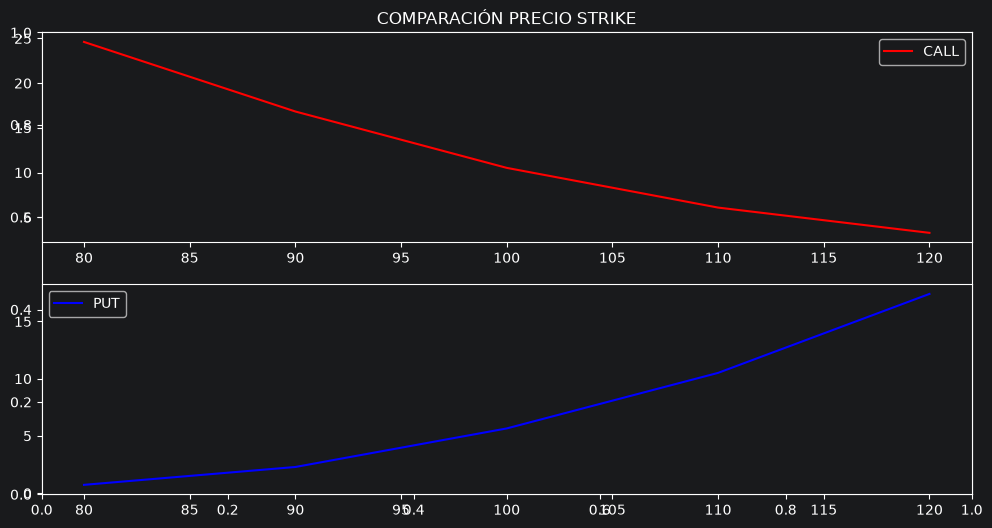

,call,put,dif_call,dif_put
80,24.610394,0.716989,NaN,NaN
90,16.830455,2.278508,-7.779939,1.561519
100,10.526499,5.649210,-6.303956,3.370701
110,6.084310,10.507287,-4.442189,4.858077
120,3.259181,17.410372,-2.825130,6.903085


In [78]:
call_K = []
put_K = []
for Ko in K_movil:
    prima_call, precios_call, payoffs_call = monte_carlo_option_pricer(S0, Ko, T, r, sigma, num_simulaciones, 252, option_type='call')
    prima_put, precios_put, payoffs_put = monte_carlo_option_pricer(S0, Ko, T, r, sigma, num_simulaciones, 252, option_type='put')
    call_K.append(prima_call)
    put_K.append(prima_put)

plt.figure(figsize=(12, 6))
plt.title('COMPARACIÓN PRECIO STRIKE')

plt.subplot(2,1,1)

plt.plot(K_movil,call_K, color='red', label='CALL')
plt.legend()

plt.subplot(2,1,2)
plt.plot(K_movil,put_K, color='BLUE', label='PUT')
plt.legend()

plt.show()

strike_sensibilidad = pd.DataFrame(data= {
    'call': call_K,
    'put': put_K,
}, index=K_movil,
)

strike_sensibilidad['dif_call'] = strike_sensibilidad['call'].diff()
strike_sensibilidad['dif_put'] = strike_sensibilidad['put'].diff()
strike_sensibilidad


### Sigma movil analisis

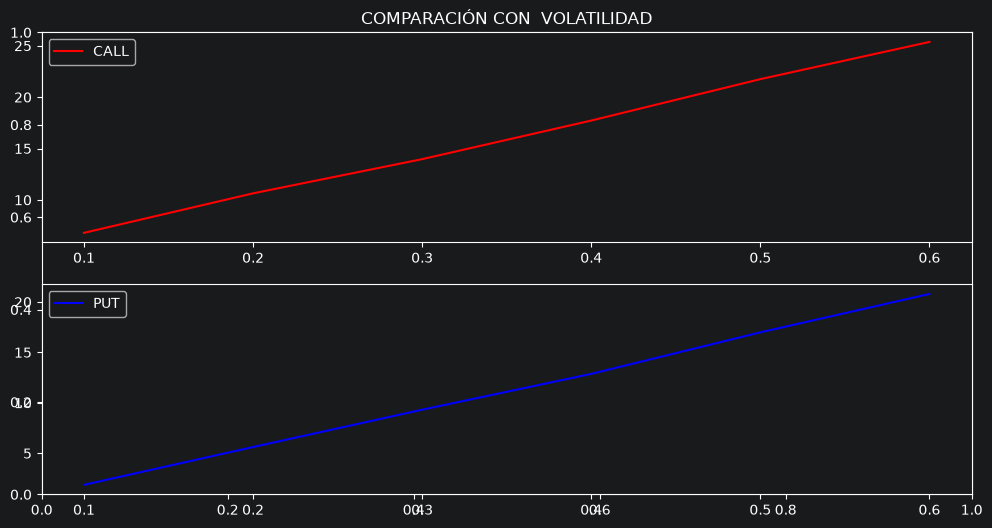

,call,put,dif_call,dif_put
0.1,6.792358,1.875814,NaN,NaN
0.2,10.637339,5.623269,3.844981,3.747454
0.3,13.966388,9.319984,3.329049,3.696716
0.4,17.722391,12.868265,3.756004,3.548281
0.5,21.753447,16.981598,4.031056,4.113333
0.6,25.374055,20.786766,3.620608,3.805168


In [81]:
call_sigma = []
put_sigma = []
for Sigma_o in sigma_movil:
    prima_call, precios_call, payoffs_call = monte_carlo_option_pricer(S0, K, T, r, Sigma_o, num_simulaciones, 252, option_type='call')
    prima_put, precios_put, payoffs_put = monte_carlo_option_pricer(S0, K, T, r, Sigma_o, num_simulaciones, 252, option_type='put')
    call_sigma.append(prima_call)
    put_sigma.append(prima_put)

plt.figure(figsize=(12, 6))
plt.title('COMPARACIÓN CON  VOLATILIDAD')

plt.subplot(2,1,1)

plt.plot(sigma_movil,call_sigma, color='red', label='CALL')
plt.legend()

plt.subplot(2,1,2)
plt.plot(sigma_movil,put_sigma, color='BLUE', label='PUT')
plt.legend()

plt.show()

sigma_sensibilidad = pd.DataFrame(data= {
    'call': call_sigma,
    'put': put_sigma,
}, index=sigma_movil,
)

sigma_sensibilidad['dif_call'] = sigma_sensibilidad['call'].diff()
sigma_sensibilidad['dif_put'] = sigma_sensibilidad['put'].diff()
sigma_sensibilidad

### COMPARACIÓN CON TIEMPO

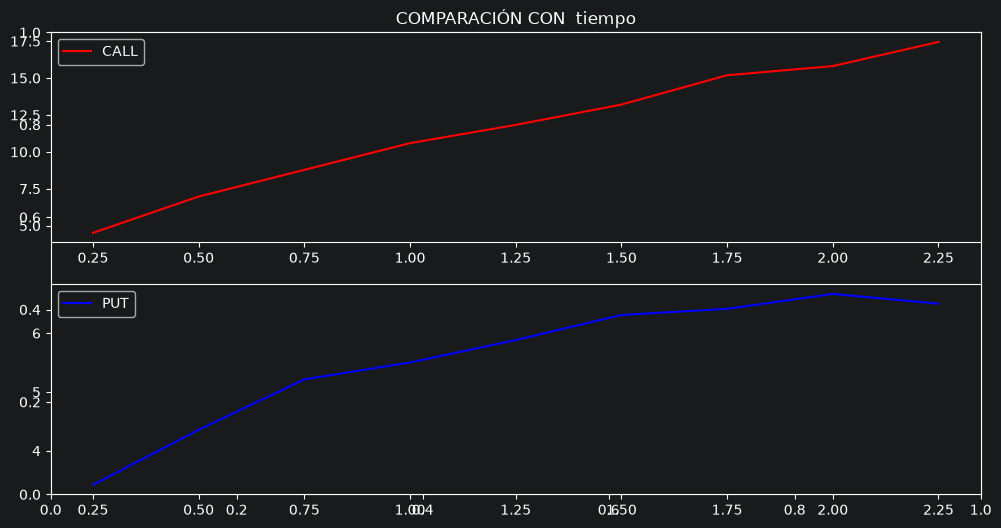

,call,put,dif_call,dif_put
0.25,4.513501,3.420910,NaN,NaN
0.50,6.971392,4.355948,2.457891,0.935039
0.75,8.780744,5.213408,1.809352,0.857460
1.00,10.590905,5.501219,1.810161,0.287811
1.25,11.825677,5.882138,1.234772,0.380919
1.50,13.203508,6.308671,1.377831,0.426533
1.75,15.189372,6.412738,1.985864,0.104067
2.00,15.810520,6.666575,0.621148,0.253837
2.25,17.446995,6.501047,1.636475,-0.165528


In [84]:
call_T = []
put_T = []
for To in T_movil:
    prima_call, precios_call, payoffs_call = monte_carlo_option_pricer(S0, K, To, r, sigma, num_simulaciones, 252, option_type='call')
    prima_put, precios_put, payoffs_put = monte_carlo_option_pricer(S0, K, To, r, sigma, num_simulaciones, 252, option_type='put')
    call_T.append(prima_call)
    put_T.append(prima_put)

plt.figure(figsize=(12, 6))
plt.title('COMPARACIÓN CON  tiempo')

plt.subplot(2,1,1)

plt.plot(T_movil,call_T, color='red', label='CALL')
plt.legend()

plt.subplot(2,1,2)
plt.plot(T_movil,put_T, color='BLUE', label='PUT')
plt.legend()

plt.show()
T_sensibilidad = pd.DataFrame(data= {
    'call': call_T,
    'put': put_T,
}, index=T_movil,
)

T_sensibilidad['dif_call'] = T_sensibilidad['call'].diff()
T_sensibilidad['dif_put'] = T_sensibilidad['put'].diff()
T_sensibilidad

Es importante aclarar que la impacto en put es menor debido al efecto del valor presente sobre el valor

### ANALISIS CON RENDIMEINTO

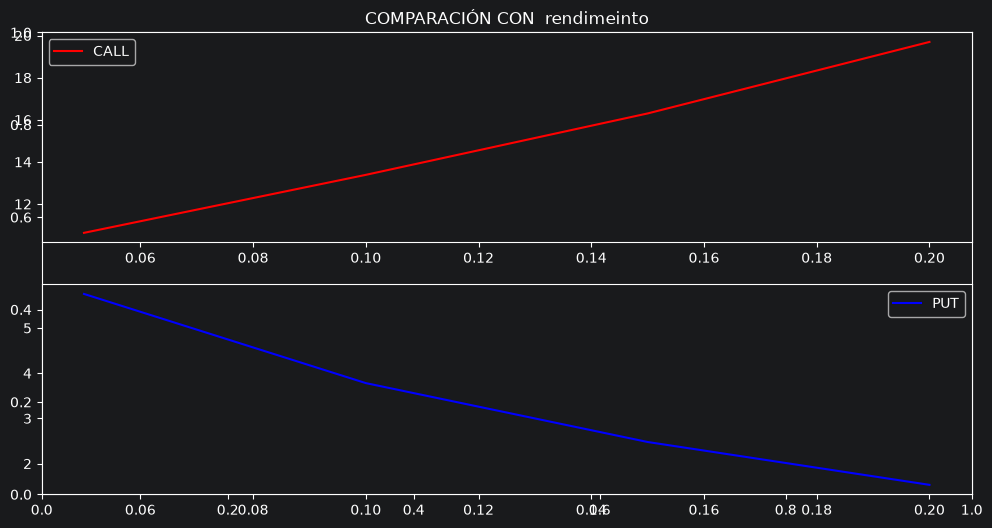

,call,put,dif_call,dif_put
0.05,10.631609,5.755654,NaN,NaN
0.10,13.385304,3.781854,2.753695,-1.973800
0.15,16.301337,2.478226,2.916033,-1.303628
0.20,19.697322,1.529642,3.395985,-0.948584


In [85]:
call_R = []
put_R = []
for ro in r_movil:
    prima_call, precios_call, payoffs_call = monte_carlo_option_pricer(S0, K, T, ro, sigma, num_simulaciones, 252, option_type='call')
    prima_put, precios_put, payoffs_put = monte_carlo_option_pricer(S0, K, T, ro, sigma, num_simulaciones, 252, option_type='put')
    call_R.append(prima_call)
    put_R.append(prima_put)

plt.figure(figsize=(12, 6))
plt.title('COMPARACIÓN CON  rendimeinto')

plt.subplot(2,1,1)

plt.plot(r_movil,call_R, color='red', label='CALL')
plt.legend()

plt.subplot(2,1,2)
plt.plot(r_movil,put_R, color='BLUE', label='PUT')
plt.legend()
plt.show()
r_sensibilidad = pd.DataFrame(data= {
    'call': call_R,
    'put': put_R,
}, index=r_movil,
)

r_sensibilidad['dif_call'] = r_sensibilidad['call'].diff()
r_sensibilidad['dif_put'] = r_sensibilidad['put'].diff()
r_sensibilidad

## INTERPRETACIONES
Precio del activo

¿Por qué una call aumenta cuando aumenta el precio de la acción?

- Porque la oportunidad de ganar dinero es mucho más certera debido a su cercanía con el strike price además de que su formula de payoff lo represneta: max(0,So -K)

¿Por qué una put se comporta de manera distinta?

- Porque la probbailidad de sacar un payoff positivo resulta menos probabable por la distancia con el strike price

- Volatilidad

¿Por qué una mayor incertidumbre aumenta o disminuye el valor de la opción?

Porque vuelve más o menos probable (representado en la amplitud de escenario) conseguir payoff en ambos sentidos del lado del LONG que la ganancia es infinita en el caso de SHORT no es conveniente

Tiempo


¿Siempre es deseable tener más tiempo?
NO, en primera instancia el efecto a la larga es distinto en ambos contratos; segunda aumentas la incertidumbre

¿Para quién resulta favorable?

Para el call, ya que el efecto del valor presenta retarda el payoff de put

Strike

¿Cómo modifica el strike la probabilidad de termina in-the-money?

El aumento del strike price mejora la probabildiad de put, y empeora la call debido al valor más alto que alcanzar.

Definir in-the-money

In the money, es el termino para decir que un opción ya genera un payoff al que lo posee

## Si fueras un inversionista, ¿cuál parámetro consideras más importante monitorear? ¿Por qué? Justifica usando tus resultados

No pondrían tanta atención al strike porque eso se define a un inicio de la compora y normalmente debería parecer adecuado según las necesidades de cobertura por las que compré. Una vez adquirido, el precio spot es primordial porque inidca que zona out o in the money te encuentras. Posteriormente si yo emiti el contrato monitorear la volatilidad es importante para coberturizar, si no es así de igual forma es importante.

## TRABAJO EN CLASE
no hacer mucho caso, pero son los analisis para cada precio en call según el cambio en los parametros

In [56]:
S0 = 100
K = 100
T = 1.0
r = 0.05
sigma = 0.20
num_simulations = 100000
num_steps = 252

call_price, simulaciones, payoffs = monte_carlo_option_pricer(S0, K, T, r, sigma, num_simulations, num_steps, option_type='call')
print(f"Precio estimado de la Opción Call Europea: {call_price:.4f}")



Precio estimado de la Opción Call Europea: 10.4495


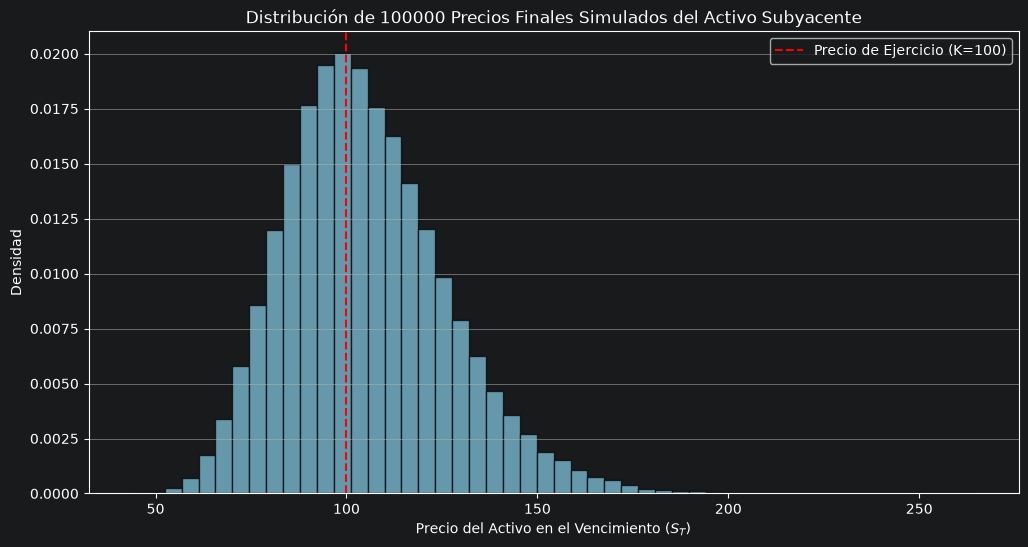

In [57]:
plt.figure(figsize=(12, 6))
plt.hist(simulaciones, bins=50, density=True, alpha=0.7, color='skyblue', edgecolor='black')
plt.axvline(K, color='red', linestyle='--', label=f'Precio de Ejercicio (K={K})')
plt.title(f'Distribución de {num_simulations} Precios Finales Simulados del Activo Subyacente')
plt.xlabel('Precio del Activo en el Vencimiento ($S_T$)')
plt.ylabel('Densidad')
plt.grid(axis='y', alpha=0.75)
plt.legend()
plt.show()

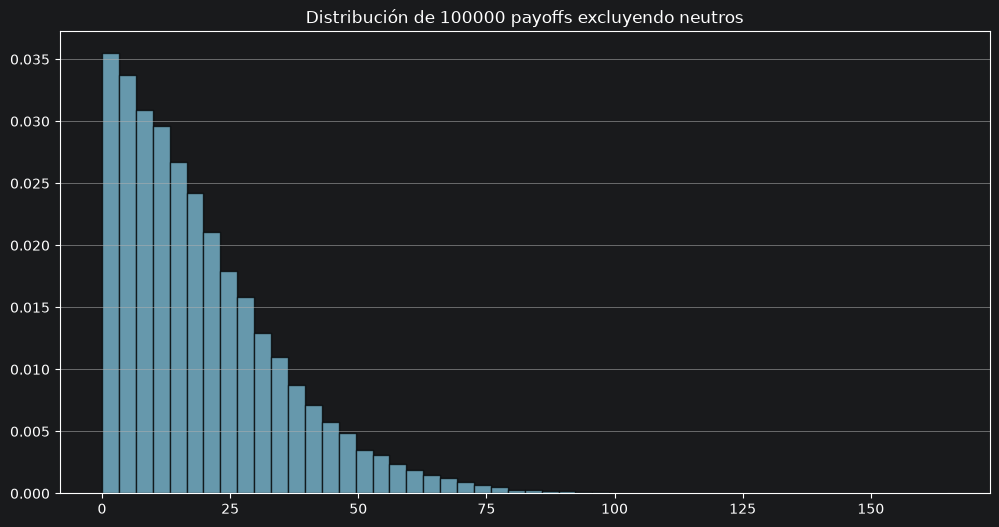

In [58]:
plt.figure(figsize=(12, 6))
plt.hist(payoffs[payoffs>0], bins=50, density=True, alpha=0.7, color='skyblue', edgecolor='black')
plt.title(f'Distribución de {num_simulations} payoffs excluyendo neutros')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [59]:
np.mean(payoffs)

np.float64(10.985280227728262)

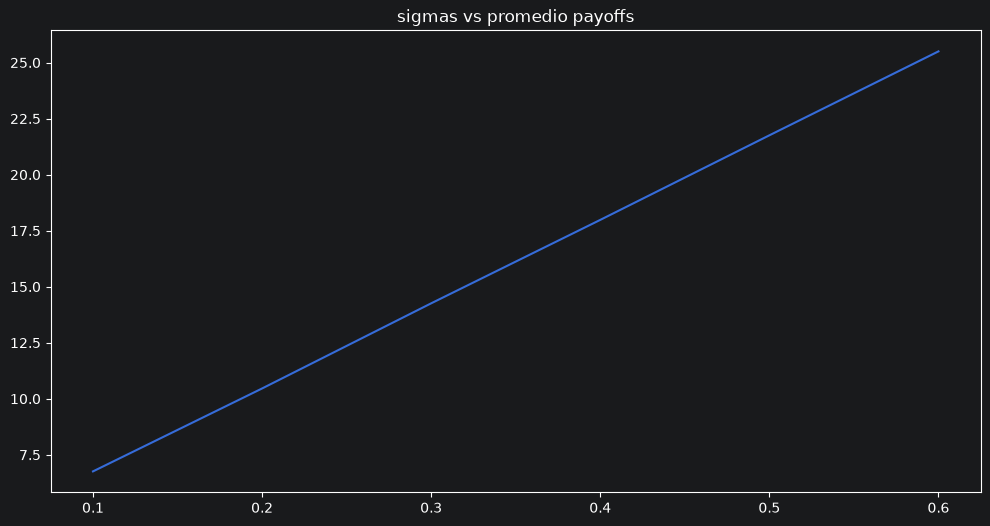

               0
count   5.000000
mean   39.401700
std     0.415340
min    38.894524
25%    39.135478
50%    39.369948
75%    39.668656
max    39.939894


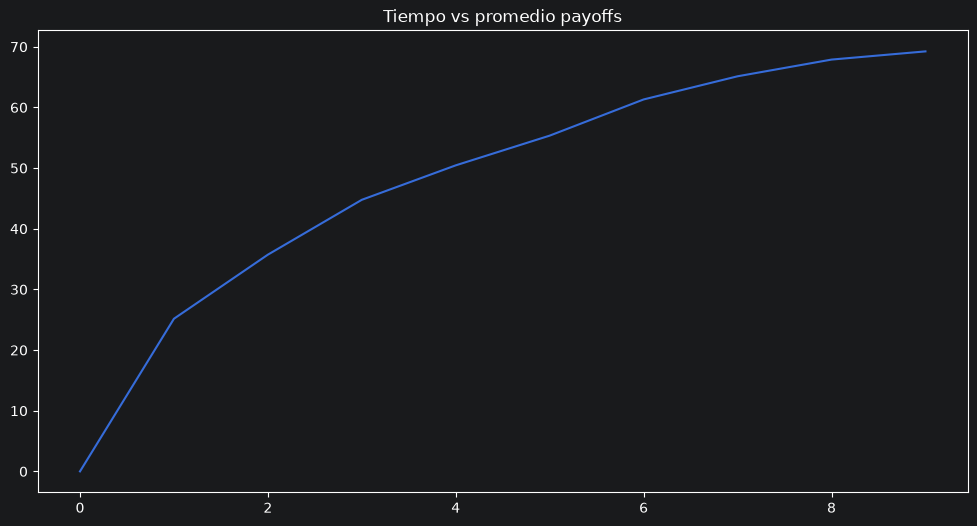

                0
count   10.000000
mean    63.570630
std     34.708420
min      0.000000
25%     42.618077
50%     66.346555
75%     90.013656
max    108.586931


In [60]:
sigmas = np.arange(.10,.70, .10)
tiempos = np.arange(0,10,1)
sigma = .20
call_prices = []
simulaciones = []
payoffs_mean = []


for sigma in sigmas:
    call_price, simulacion, payoffs = monte_carlo_option_pricer(S0, K, T, r, sigma, num_simulations, num_steps, option_type='call')
    call_prices.append(call_price)
    payoffs_mean.append(payoffs.mean())

plt.figure(figsize=(12, 6))
plt.title("sigmas vs promedio payoffs")
plt.plot(sigmas, call_prices, label='Call Europea')
plt.show()

payoffs_mean = pd.DataFrame(payoffs_mean)
sensibildad = (payoffs_mean - payoffs_mean.shift(1))/ .10
print(sensibildad.describe())

call_prices = []
simulaciones = []
payoffs_mean = []

for T in tiempos:
    call_price, simulacion, payoffs = monte_carlo_option_pricer(S0, K, T, r, sigma, num_simulations, num_steps, option_type='call')
    call_prices.append(call_price)
    payoffs_mean.append(payoffs.mean())

plt.figure(figsize=(12, 6))
plt.title("Tiempo vs promedio payoffs")
plt.plot(tiempos, call_prices, label='Call Europea')
plt.show()

payoffs_mean = pd.DataFrame(payoffs_mean)
print(payoffs_mean.describe())


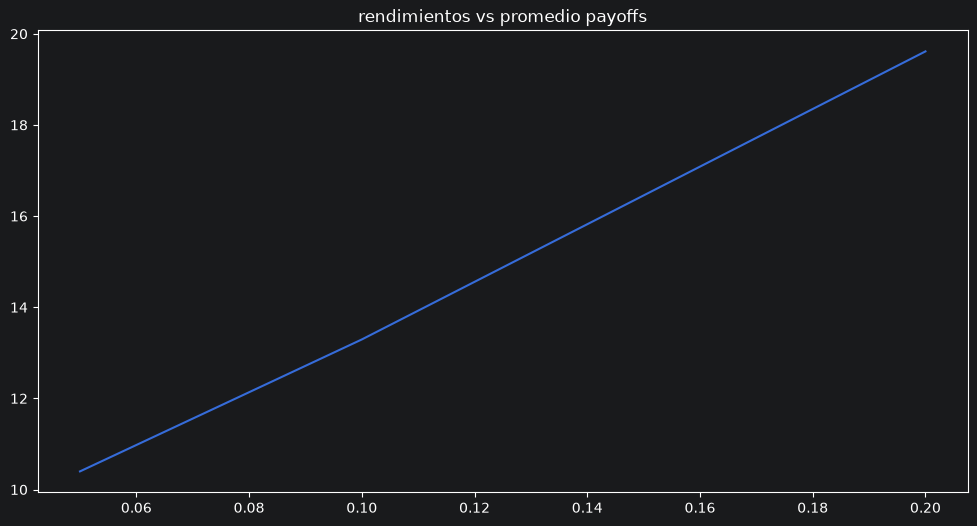

,0
0,10.930867
1,14.690666
2,23.956275


In [61]:
#comparamps enn base a los rendimeintos

rendimientos = [.05,.10,.20]
T = 1
sigma = .20
call_prices = []
simulaciones = []
payoffs_mean = []
for r in rendimientos:
    call_price, simulacion, payoffs = monte_carlo_option_pricer(S0, K, T, r, sigma, num_simulations, num_steps, option_type='call')
    call_prices.append(call_price)
    payoffs_mean.append(payoffs.mean())

plt.figure(figsize=(12, 6))
plt.plot(rendimientos, call_prices, label='Call Europea')
plt.title("rendimientos vs promedio payoffs")
plt.show()

payoffs_mean = pd.DataFrame(payoffs_mean)
payoffs_mean

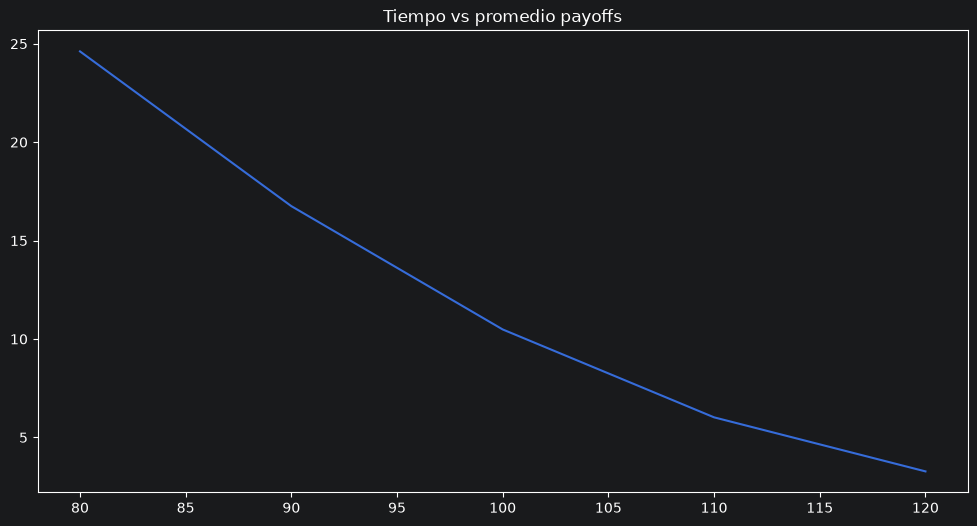

,0
0,25.872533
1,17.606817
2,11.021252
3,6.327814
4,3.441277


In [62]:
strikes = np.arange(80,130,10)

T = 1
sigma = .20
r = .05
num_simulations = 100000


call_prices = []
simulaciones = []
payoffs_mean = []
for K in strikes:
    call_price, simulacion, payoffs = monte_carlo_option_pricer(S0, K, T, r, sigma, num_simulations, num_steps, option_type='call')
    call_prices.append(call_price)
    payoffs_mean.append(payoffs.mean())

plt.figure(figsize=(12, 6))
plt.plot(strikes, call_prices, label='Call Europea')
plt.title("Tiempo vs promedio payoffs")
plt.show()

payoffs_mean = pd.DataFrame(payoffs_mean)
payoffs_mean

